# Slide 24: the KBM dataset, extent ratio per field against WIDTH (one figure for TGLF, one for GFTM)

Fusion_PhD-qp5.31 (STEP GK talk, 2 Nov 2026). Format of `fig6_extent_vs_width_per_nbasis` of `tglf_quadrature_extent.ipynb` /
`gftm_quadrature_extent.ipynb` (branches `analysis/{tglf,gftm}-quadrature-extent-bpar`) with the user's changes: 3 NBASIS per code,
raw medians only (no red line, no grey band), and no $B_\parallel$ for GFTM ("we don't know if it's been done correctly").

- Population: GS2-KBM samples (user classifier) of the SPR-045 / M1 `kbm_8d` hypercubes, 119 / 161 (as slides 9 and 19).
- TGLF `TGLF/Runs/kbm_tglf_nbasis/<db>/nb<N>_nx32_fp2p0_<w>`: FILTER 2, NBASIS_MAX 8/16/32. Fields $\phi$, $A_\parallel$, $B_\parallel$.
- GFTM (stock) `GFTM/Runs/LATIN_HYPERCUBE/<db>/kbm_8d/{wo_f05_<w>, qx_f05_<w>_nb<N>_nx<X>}`: FILTER 0.5, NBASIS 22/43/59. Fields $\phi$, $A_\parallel$.
- Metric as the source figure: median over the population of $|\log_{10}(\mathrm{Extent}_{\rm code}/\mathrm{Extent}_{\rm GS2})|$, each field
  against GS2's same field, dominant mode (argmax $\gamma$, $\gamma > 0$). Extent = pyro `Extent` at 95%. GS2: final-time `pyro_cube`.

In [1]:
from pathlib import Path
import os
import warnings
from dotenv import load_dotenv
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "pyproject.toml").is_file() and (path / "notebooks").is_dir())
plt.style.use(ROOT / "src/general_analysis/paper.mplstyle")
# slide-readable at the saved size, white background (user, 2026-11-01)
plt.rcParams.update({"font.size": 20, "axes.labelsize": 22, "axes.titlesize": 22, "xtick.labelsize": 20, "ytick.labelsize": 20,
                     "legend.fontsize": 19, "lines.linewidth": 2.5, "lines.marker": "", "figure.facecolor": "white",
                     "axes.facecolor": "white", "savefig.facecolor": "white", "savefig.dpi": 200})
load_dotenv(ROOT / "local.env", override=True)
warnings.filterwarnings("ignore")
plots_dir = ROOT / "Plots" / "stepgk_20261102"
plots_dir.mkdir(parents=True, exist_ok=True)


def log_xticks(ax, ticks):
    ax.set_xticks(ticks)
    ax.xaxis.set_major_formatter(StrMethodFormatter("{x:g}"))
    ax.minorticks_off()
import json
from multiprocessing import get_context
import pandas as pd
from pyrokinetics import PyroHypercube
from pyrokinetics.pyroscan import PyroScanGKOutput
from pyrokinetics.diagnostics.extent import Extent
from general_analysis import mode_classification as mc

data_root = Path(os.environ["GK_DATA_ROOT"]).expanduser()
lhc = data_root / "GS2" / "Runs" / "LATIN_HYPERCUBE"
databases = ["SPR-045", "M1"]
fraction = 0.95
field_labels = {"phi": r"$\phi$", "apar": r"$A_\parallel$", "bpar": r"$B_\parallel$"}
field_colours = {"phi": "C0", "apar": "C3", "bpar": "C2"}     # the source figure's colours
code_fields = {"TGLF": ["phi", "apar", "bpar"], "GFTM": ["phi", "apar"]}
tglf_nbasis = [8, 16, 32]                    # NXGRID 32
gftm_sections = {22: 28, 43: 49, 59: 65}     # NBASIS: NXGRID
n_workers = int(os.environ.get("SLURM_CPUS_PER_TASK", 4))

In [2]:
gs2 = {}
for database in databases:
    gs2_dir = lhc / database / "kbm_8d"
    gs2_scan = mc.attach_legacy_funcs(PyroHypercube(pyroscan_json=gs2_dir / "pyro_cube" / "pyroscan.json", load_base_pyro=True))
    gs2_scan.load_gk_output(netcdf_file=gs2_dir / "pyro_cube" / "cube.nc")
    gs2_avg_scan = PyroHypercube(pyroscan_json=gs2_dir / "pyro_cube_avg" / "pyroscan.json", load_base_pyro=True)
    gs2_avg_scan.load_gk_output(netcdf_file=gs2_dir / "pyro_cube_avg" / "cube.nc")
    gamma_gs2 = gs2_avg_scan.gk_output.data.growth_rate.pint.dequantify().values.ravel()
    kbm = (np.asarray(mc.classify(mc.indicators(gs2_scan, gs2_scan.gk_output.data))) == "KBM") & np.isfinite(gamma_gs2) & (gamma_gs2 > 0)
    Extent(gs2_scan.gk_output, fraction=fraction)
    gs2_extent = gs2_scan.gk_output.data.extent.pint.dequantify().transpose("sample", ...)
    print(database, "GS2-KBM:", kbm.sum(), "| GS2 extent dims", dict(gs2_extent.sizes))
    gs2[database] = dict(names=gs2_scan.gk_output.data.sample_name.values.astype(str)[kbm],
                         extent={field: gs2_extent.sel(field=field).values.reshape(len(kbm), -1)[kbm, 0] for field in field_labels})
    print("   median GS2 extent (rad):", {field: round(float(np.nanmedian(value)), 3) for field, value in gs2[database]["extent"].items()})

SPR-045 GS2-KBM: 119 | GS2 extent dims {'sample': 300, 'field': 3}
   median GS2 extent (rad): {'phi': 2.733, 'apar': 2.497, 'bpar': 2.303}


M1 GS2-KBM: 161 | GS2 extent dims {'sample': 300, 'field': 3}
   median GS2 extent (rad): {'phi': 2.664, 'apar': 2.505, 'bpar': 2.105}


In [3]:
def extent_errors(output, database, fields):
    Extent(output, fraction=fraction)
    data = output.data.set_index(sample="sample_name").sel(sample=gs2[database]["names"])
    growth = data.growth_rate.pint.dequantify().fillna(-np.inf).transpose("sample", "mode")
    mode = growth.argmax("mode")
    unstable = growth.isel(mode=mode).values > 0
    extent = data.extent.pint.dequantify().transpose("sample", "field", "mode").isel(mode=mode)
    return {field: float(np.nanmedian(np.where(unstable, np.abs(np.log10(extent.sel(field=field).values / gs2[database]["extent"][field])), np.nan)))
            for field in fields}


def load_tglf(leaf):
    tglf_scan = PyroHypercube(pyroscan_json=leaf / "pyroscan.json", load_base_pyro=True)
    tglf_scan.load_gk_output(netcdf_file=leaf / "pyroscan.nc")
    flags = json.loads((leaf / "manifest.json").read_text())["code_flags"]
    assert float(flags["FILTER"]) == 2.0 and int(flags["NXGRID"]) == 32
    return dict(code="TGLF", database=leaf.parent.name, nbasis=int(flags["NBASIS_MAX"]),
                width=round(float(tglf_scan.base_pyro.gk_input.data["width"]), 4), **extent_errors(tglf_scan.gk_output, leaf.parent.name, code_fields["TGLF"]))


def load_gftm(leaf):
    database = leaf.parent.parent.name
    nbasis = 22 if leaf.name.startswith("wo_f05_") else int(leaf.name.split("_nb")[1].split("_")[0])
    netcdf = leaf / "pyro_cube" / "cube.nc" if (leaf / "pyro_cube" / "cube.nc").is_file() else leaf / "pyroscan.nc"
    return dict(code="GFTM", database=database, nbasis=nbasis, width=round(float(leaf.name.split("_")[2][1:].replace("p", ".")), 4),
                **extent_errors(PyroScanGKOutput.from_netcdf(netcdf), database, code_fields["GFTM"]))


tglf_leaves = [leaf for database in databases for nbasis in tglf_nbasis
               for leaf in sorted((data_root / "TGLF" / "Runs" / "kbm_tglf_nbasis" / database).glob(f"nb{nbasis}_nx32_fp2p0_*"))]
gftm_dir = lambda database: data_root / "GFTM" / "Runs" / "LATIN_HYPERCUBE" / database / "kbm_8d"
gftm_leaves = [leaf for database in databases for leaf in sorted(gftm_dir(database).glob("wo_f05_w*")) +
               [leaf for nbasis, nxgrid in gftm_sections.items() if nbasis != 22 for leaf in sorted(gftm_dir(database).glob(f"qx_f05_w*_nb{nbasis}_nx{nxgrid}"))]]
with get_context("fork").Pool(n_workers) as pool:
    medians = pd.DataFrame(pool.map(load_tglf, tglf_leaves, chunksize=2) + pool.map(load_gftm, gftm_leaves, chunksize=2)).sort_values(["code", "database", "nbasis", "width"])
print(medians.groupby(["code", "database", "nbasis"]).width.nunique().unstack().to_string())

nbasis           8     16    22    32    43    59
code database                                    
GFTM M1         NaN   NaN  59.0   NaN  66.0  66.0
     SPR-045    NaN   NaN  59.0   NaN  66.0  66.0
TGLF M1        24.0  24.0   NaN  24.0   NaN   NaN
     SPR-045   24.0  24.0   NaN  24.0   NaN   NaN


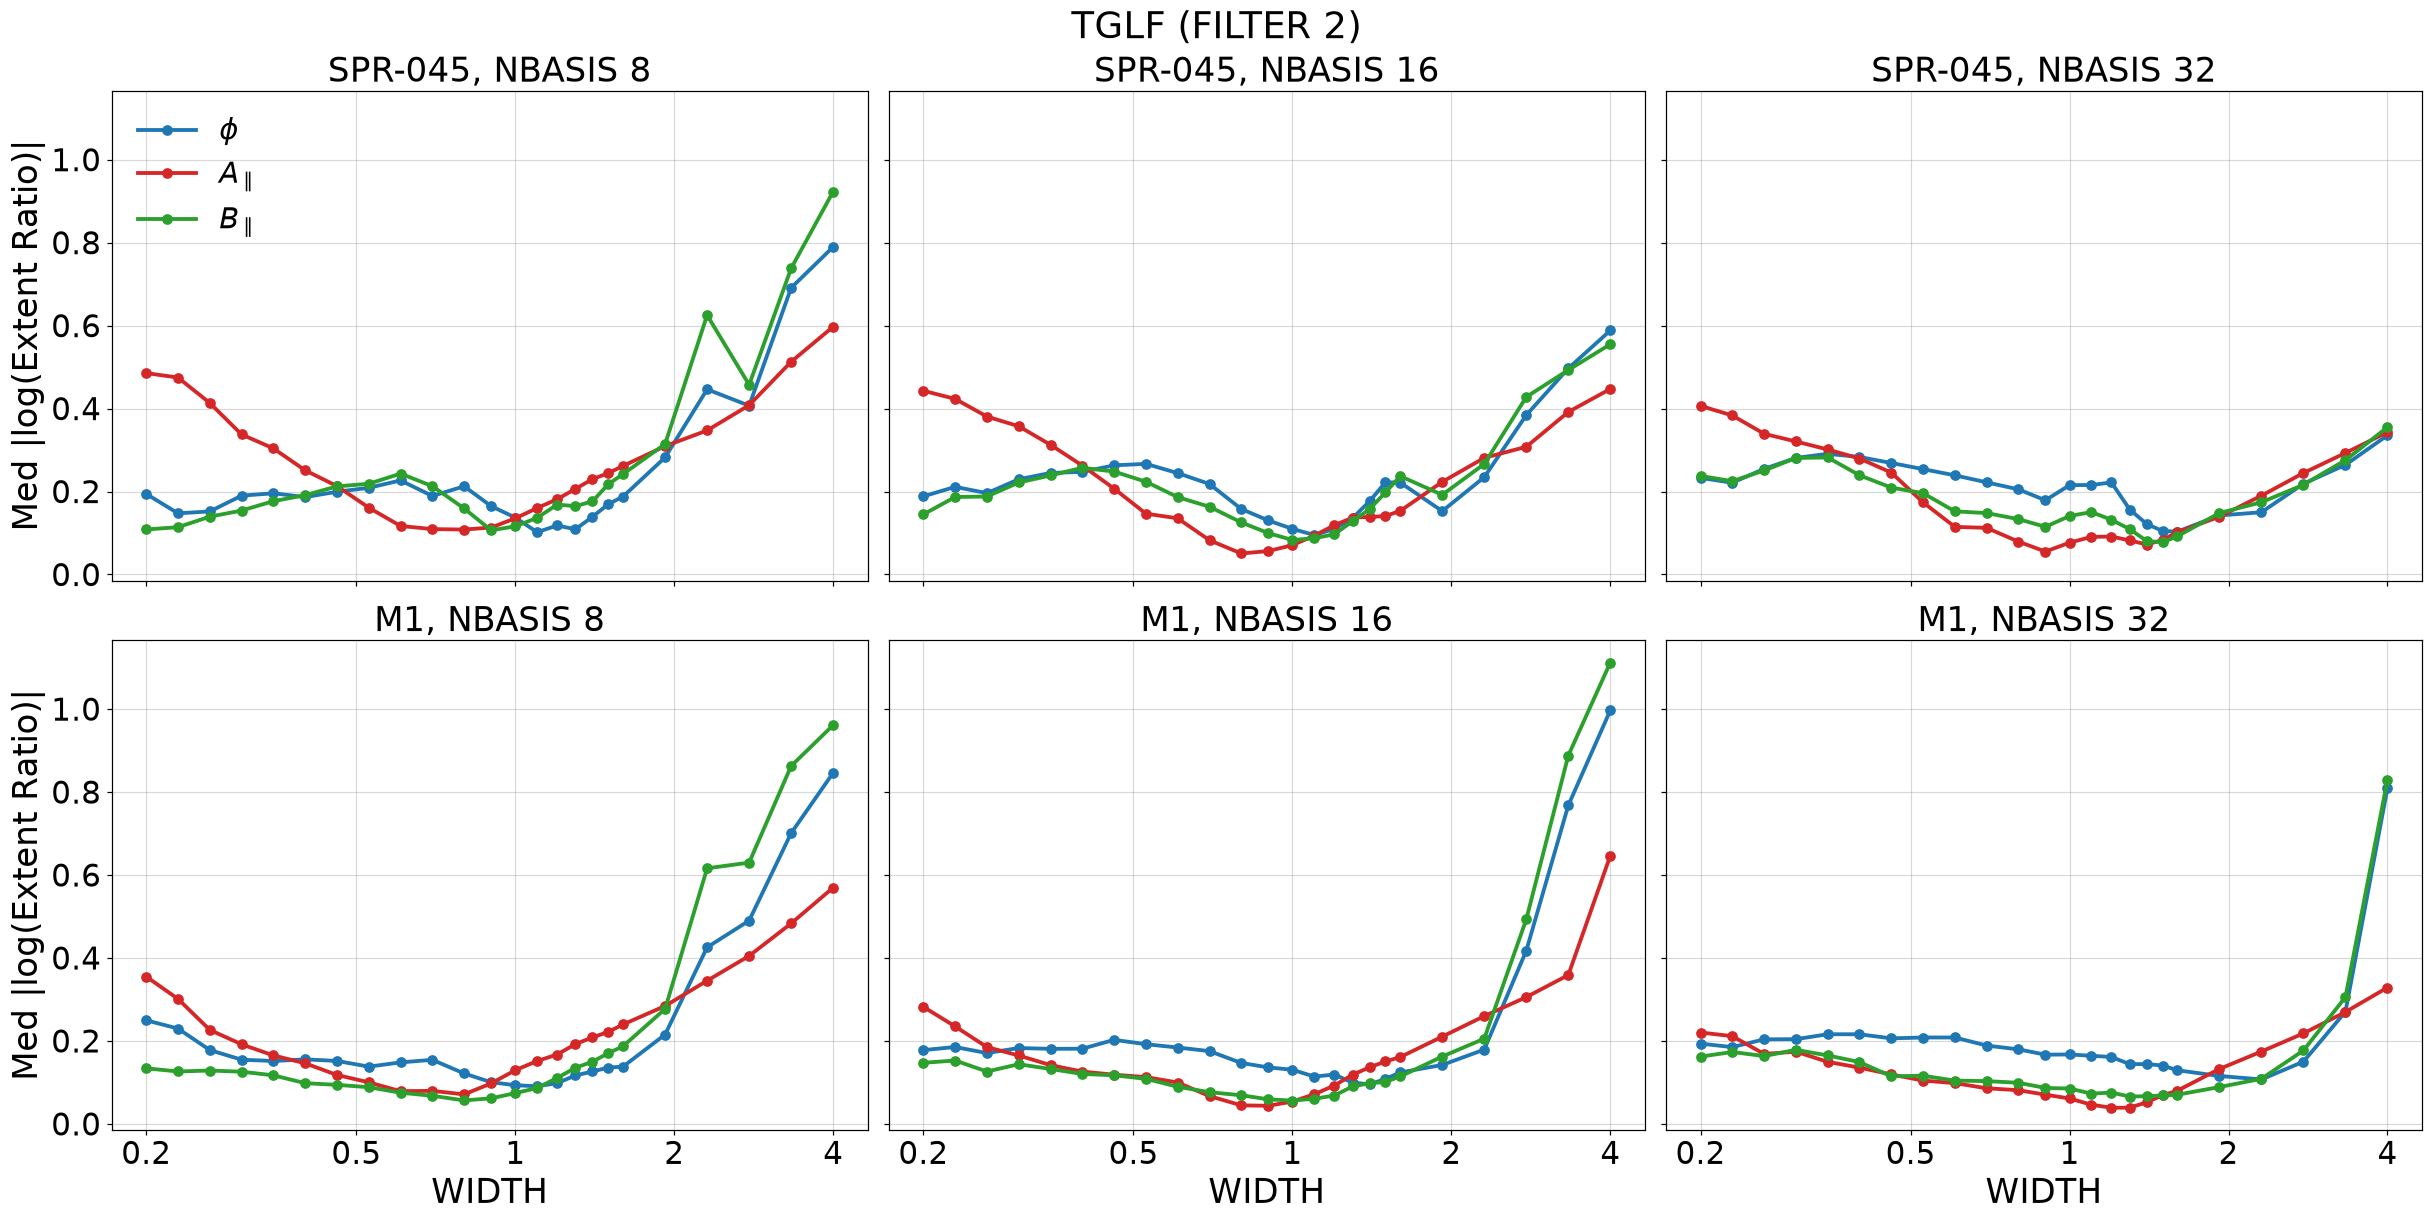

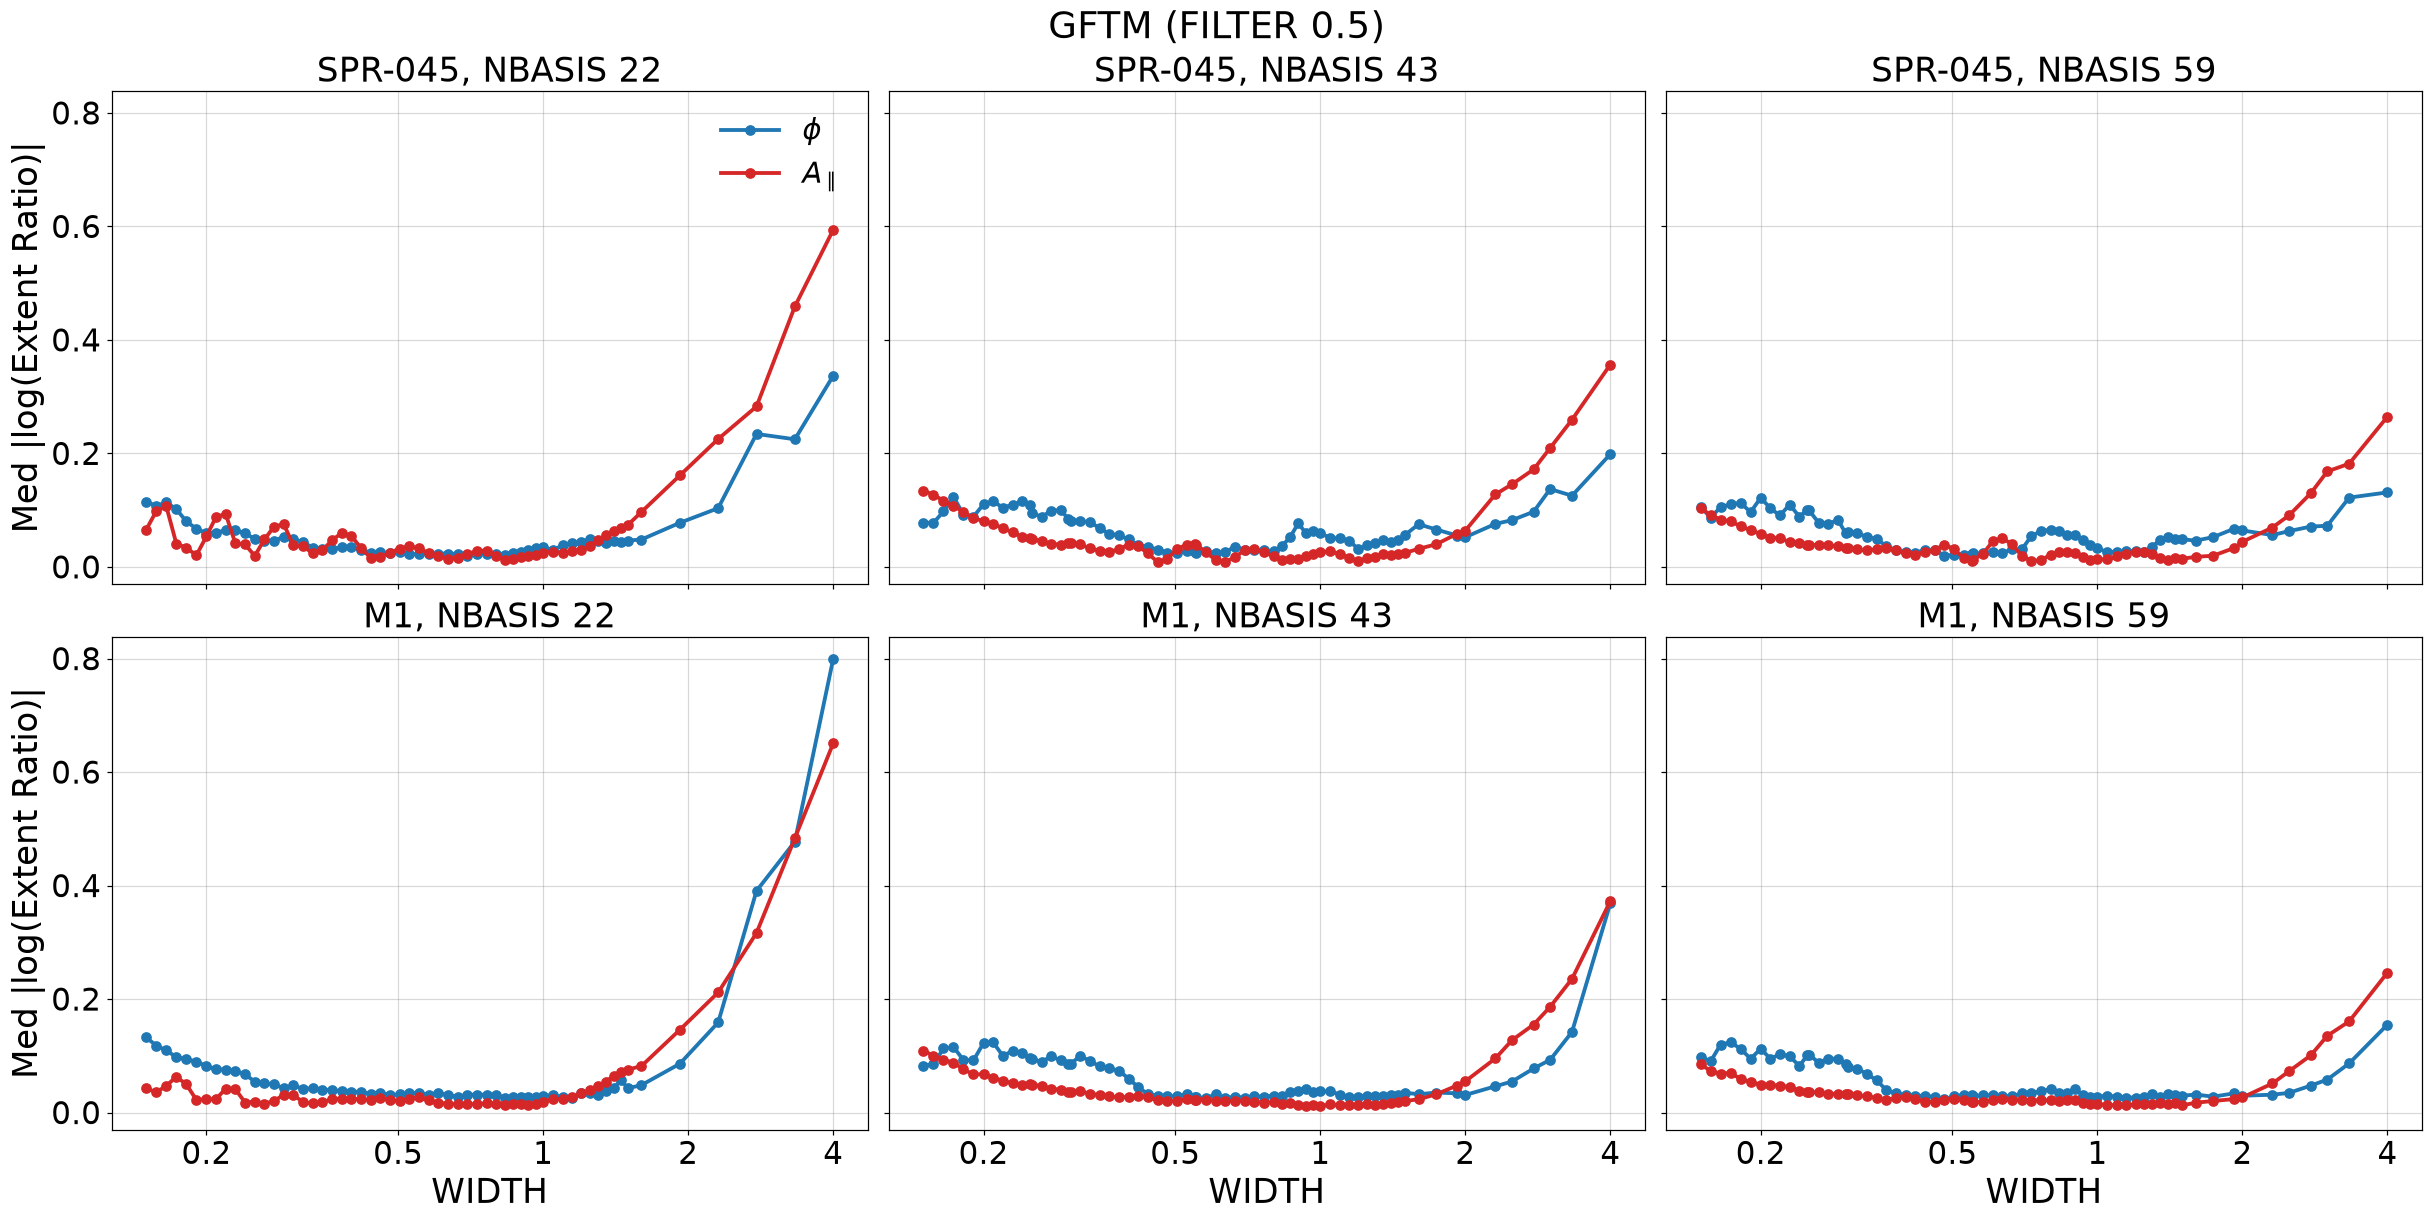

In [4]:
for code, nbasis_list in (("TGLF", tglf_nbasis), ("GFTM", list(gftm_sections))):
    fig, axes = plt.subplots(len(databases), len(nbasis_list), figsize=(22, 11), sharex=True, sharey=True, squeeze=False)
    for row, database in enumerate(databases):
        for column, nbasis in enumerate(nbasis_list):
            ax = axes[row, column]
            leaf_medians = medians[(medians.code == code) & (medians.database == database) & (medians.nbasis == nbasis)]
            for field in code_fields[code]:
                ax.plot(leaf_medians.width, leaf_medians[field], color=field_colours[field], marker="o", ms=6, label=field_labels[field])
            ax.set(xscale="log")
            ax.set_title(f"{database}, NBASIS {nbasis}")
            if row == len(databases) - 1:
                ax.set_xlabel("WIDTH")
                log_xticks(ax, [0.2, 0.5, 1, 2, 4])
        axes[row, 0].set_ylabel("Med |log(Extent Ratio)|")
    axes[0, 0].legend()
    fig.suptitle(f"{code} ({'FILTER 2' if code == 'TGLF' else 'FILTER 0.5'})", fontsize=24)
    fig.savefig(plots_dir / f"fig_slide24_{code.lower()}_extent_per_field.png", bbox_inches="tight")
    plt.show()